# Jednorazowa ocena na zbiorze testowym, audyt podgrup i porównanie modeli

----
## 0. Importy

In [1]:
import sys, json, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
from src import config as cfg
from src.data import load_data, load_splits
from src.features import build_base_frame
from src.models import load_predictions
from src.metrics import metrics, bootstrap_ci, bootstrap_gini_diff
from src.calibration import calib_report
warnings.filterwarnings('ignore')
plt.style.use('default')

----
## 1. Predykcje testowe

In [2]:
df = load_data(); splits = load_splits(); y = df[cfg.TARGET]
te = splits['test']; y_te = y.loc[te].to_numpy()
raw = {m: load_predictions(k).set_index('id') for m, k in [('logit', 'logit'), ('black-box', 'lgbm_mono')]}
P_raw = {m: d[d.zbior == 'test'].loc[te, 'p'].to_numpy() for m, d in raw.items()}
cal = pd.read_csv(cfg.ROOT / 'outputs/predictions/pd_skalibrowane.csv')
P_4 = {m: cal[(cal.model == m) & (cal.zbior == 'test')].set_index('id').loc[te, 'pd_4proc'].to_numpy() for m in P_raw}
print(f'test: {len(te)} firm, {y_te.sum()} defaultów, DR = {y_te.mean():.2%}')

test: 450 firm, 62 defaultów, DR = 13.78%


----
## 2. Skuteczność na teście

In [3]:
rows = []
for m in P_raw:
    met = metrics(y_te, P_raw[m]); ci = bootstrap_ci(y_te, P_raw[m])
    rows.append({'model': m, **{k: met[k] for k in ['AUC', 'Gini', 'KS', 'PR-AUC', 'log-loss', 'Brier']},
                 **{f'{k} 95% CI': f'[{ci.loc[k, "CI 2,5%"]:.3f}; {ci.loc[k, "CI 97,5%"]:.3f}]' for k in ['Gini', 'KS', 'PR-AUC']}})
test_tab = pd.DataFrame(rows).set_index('model')
d, (lo, hi) = bootstrap_gini_diff(y_te, P_raw['logit'], P_raw['black-box'])
print(f'ΔGini (black-box − logit) na teście: {d:+.3f}, 95% CI [{lo:+.3f}; {hi:+.3f}]')
test_tab.to_csv(cfg.TAB_DIR / '08_test_skutecznosc.csv')
test_tab.round(4)

ΔGini (black-box − logit) na teście: +0.042, 95% CI [-0.010; +0.091]


,AUC,Gini,KS,PR-AUC,log-loss,Brier,Gini 95% CI,KS 95% CI,PR-AUC 95% CI
model,,,,,,,,,
logit,0.7079,0.4158,0.3392,0.3142,0.3667,0.1099,[0.295; 0.549],[0.251; 0.463],[0.220; 0.441]
black-box,0.7304,0.4608,0.3471,0.3018,0.3583,0.1086,[0.339; 0.590],[0.287; 0.483],[0.218; 0.419]


**Wnioski:** black-box ma Gini 0,46 vs 0,42 dla logitu. ΔGini = +0,042 z przedziałem [−0,010; +0,091] – przedział obejmuje 0, więc przewaga nie jest istotna statystycznie.

----
## 3. Krzywe ROC i PR

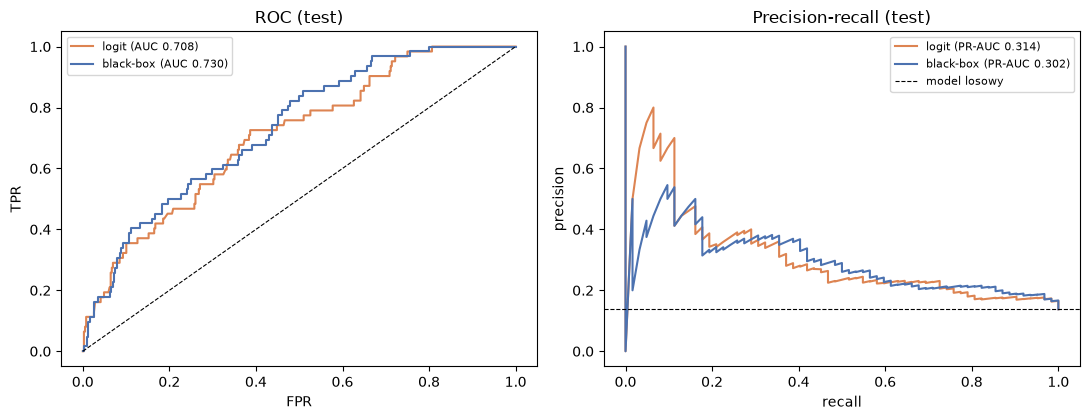

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

for m, col in zip(P_raw, ['#DD8452', '#4C72B0']):
    fpr, tpr, _ = roc_curve(y_te, P_raw[m]); axes[0].plot(fpr, tpr, c=col, label=f"{m} (AUC {test_tab.loc[m, 'AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, P_raw[m]); axes[1].plot(rc, pr, c=col, label=f"{m} (PR-AUC {test_tab.loc[m, 'PR-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].set_title('ROC (test)')
axes[1].axhline(y_te.mean(), c='k', ls='--', lw=0.8, label='model losowy'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].set_title('Precision-recall (test)')

for ax in axes: ax.legend(fontsize=8)

plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '08_roc_pr_test.png', dpi=150); plt.show()

Krzywa ROC black-boxa leży nieco wyżej, a krzywe PR są prawie takie same.

----
## 4. CV vs valid vs test

In [5]:
cv_log = pd.read_csv(cfg.TAB_DIR / '03_cv_foldy.csv')
auc_cv = {'logit': (cv_log['AUC'].mean(), cv_log['AUC'].std())}
oof_bb = raw['black-box'][raw['black-box'].zbior == 'oof']
fold_auc = [metrics(y.loc[g.index], g['p'])['AUC'] for _, g in oof_bb.groupby('fold')]
auc_cv['black-box'] = (np.mean(fold_auc), np.std(fold_auc, ddof=1))
summary = pd.DataFrame({m: {'AUC CV (średnia)': auc_cv[m][0], 'AUC CV (odch. std)': auc_cv[m][1],
                            'AUC valid': metrics(y.loc[splits['valid']], raw[m][raw[m].zbior == 'valid'].loc[splits['valid'], 'p'])['AUC'],
                            'AUC test': test_tab.loc[m, 'AUC']} for m in P_raw}).T
summary.round(4)

,AUC CV (średnia),AUC CV (odch. std),AUC valid,AUC test
logit,0.7178,0.0343,0.7481,0.7079
black-box,0.7082,0.0398,0.7585,0.7304


Na CV lepszy był logit, a na valid i teście black-box. Różnice mieszczą się w rozrzucie między foldami, więc ranking modeli zależy od próby.

----
## 5. Kalibracja na teście

In [6]:
cal_tab = pd.DataFrame({m: calib_report(y_te, P_4[m]) for m in P_4}).T
cal_tab.round(4)

,DR,średnie PD,AUC,Brier,log-loss,ECE,ACE,CITL (intercept),slope
logit,0.1378,0.0360,0.7079,0.1237,0.4595,0.1031,0.1028,1.552,0.8838
black-box,0.1378,0.0359,0.7304,0.1230,0.4546,0.1033,0.1028,1.586,0.8982


Po przesunięciu do 4% średnie PD na teście wynosi ok. 3,6%, a CITL ≈ 1,55–1,59 – PD jest zaniżone względem DR 13,8%, co wynika z założenia.

----
## 6. Audyt podgrup

In [7]:
base = build_base_frame(df).loc[te]
groups = {'schemat_wsk_bilans': base['schemat_wsk_bilans'],
          'pkd_sekcja': base['pkd_sekcja'].where(base['pkd_sekcja'].map(base['pkd_sekcja'].value_counts()) >= 40, 'pozostałe')}
rows = []
for gname, g in groups.items():
    for lvl in sorted(g.unique()):
        msk = (g == lvl).to_numpy(); n_def = int(y_te[msk].sum())
        for m in P_raw:
            r = {'zmienna': gname, 'grupa': lvl, 'model': m, 'n': int(msk.sum()), 'defaulty': n_def, 'DR': y_te[msk].mean(),
                 'średnie PD (4%)': P_4[m][msk].mean(), 'Brier (surowe)': np.mean((P_raw[m][msk] - y_te[msk]) ** 2)}
            r['AUC'] = metrics(y_te[msk], P_raw[m][msk])['AUC'] if 0 < n_def < msk.sum() and n_def >= 10 else np.nan
            rows.append(r)
sub = pd.DataFrame(rows).set_index(['zmienna', 'grupa', 'model'])
sub.to_csv(cfg.TAB_DIR / '08_audyt_podgrup.csv')
sub.round(3)

n  defaulty     DR  średnie PD (4%)  \
zmienna            grupa     model                                              
schemat_wsk_bilans SFJIN     logit      229        31  0.135            0.038   
                             black-box  229        31  0.135            0.039   
                   SFJMA     logit       92        15  0.163            0.026   
                             black-box   92        15  0.163            0.031   
                   SFJMI     logit      129        16  0.124            0.039   
                             black-box  129        16  0.124            0.034   
pkd_sekcja         C         logit       52         3  0.058            0.031   
                             black-box   52         3  0.058            0.027   
                   F         logit       60        11  0.183            0.036   
                             black-box   60        11  0.183            0.033   
                   G         logit       75        10  0.133            0.039   
                             black-box   75        10  0.133            0.044   
                   L         logit       45         4  0.089            0.031   
                             black-box   45         4  0.089            0.032   
                   M         logit       77         9  0.117            0.039   
                             black-box   77         9  0.117            0.041   
                   pozostałe logit      141        25  0.177            0.036   
                             black-box  141        25  0.177            0.035   

                                        Brier (surowe)    AUC  
zmienna            grupa     model                             
schemat_wsk_bilans SFJIN     logit               0.099  0.781  
                             black-box           0.099  0.789  
                   SFJMA     logit               0.137  0.711  
                             black-box           0.137  0.716  
                   SFJMI     logit               0.110  0.611  
                             black-box           0.105  0.645  
pkd_sekcja         C         logit               0.067    NaN  
                             black-box           0.061    NaN  
                   F         logit               0.125  0.788  
                             black-box           0.124  0.809  
                   G         logit               0.123  0.665  
                             black-box           0.125  0.645  
                   L         logit               0.075    NaN  
                             black-box           0.066    NaN  
                   M         logit               0.095    NaN  
                             black-box           0.099    NaN  
                   pozostałe logit               0.131  0.722  
                             black-box           0.130  0.761

**Wnioski:** najsłabiej modele działają dla mikrofirm (SFJMI, AUC 0,61–0,64). Średnie PD w grupach jest zbliżone, mimo że DR waha się od 6% do 18% – np. w budownictwie (F) PD jest zaniżone mocniej. Małe grupy mają niepewne wyniki.

----
## 7. Porównanie modeli

In [8]:
import joblib
L = joblib.load(cfg.ROOT / 'outputs/models/logit.joblib'); B = joblib.load(cfg.ROOT / 'outputs/models/lgbm_mono.joblib')
n_bins = sum(len(L['model'].named_steps['woe'].tables_[c]) for c in L['features'])
lgbm = B['model'].named_steps['lgbm']; n_trees = lgbm.booster_.num_trees()
n_leaves = lgbm.booster_.trees_to_dataframe().query('left_child.isna()').shape[0]
imp = pd.read_csv(cfg.TAB_DIR / '05_stabilnosc.csv', index_col=0)
lime = pd.read_csv(cfg.TAB_DIR / '05_lime_wiernosc.csv')

comparison = pd.DataFrame({
    'logit (karta WoE)': {'Gini test [95% CI]': f"{test_tab.loc['logit', 'Gini']:.3f} {test_tab.loc['logit', 'Gini 95% CI']}",
                          'AUC CV ± sd': f"{auc_cv['logit'][0]:.3f} ± {auc_cv['logit'][1]:.3f}",
                          'liczba cech': len(L['features']), 'złożoność': f"{n_bins} przedziałów WoE, {len(L['features']) + 1} parametrów",
                          'interpretowalność': 'z konstrukcji (punkty karty)',
                          'stabilność wyjaśnień (Jaccard top-5 między foldami)': round(imp.loc['SHAP logit, 5 foldów', 'Jaccard top-5'], 2),
                          'wierność wyjaśnień': 'pełna (wyjaśnieniem jest sam model)',
                          'Brier test (surowe)': round(test_tab.loc['logit', 'Brier'], 4)},
    'LightGBM monotoniczny': {'Gini test [95% CI]': f"{test_tab.loc['black-box', 'Gini']:.3f} {test_tab.loc['black-box', 'Gini 95% CI']}",
                              'AUC CV ± sd': f"{auc_cv['black-box'][0]:.3f} ± {auc_cv['black-box'][1]:.3f}",
                              'liczba cech': int((lgbm.feature_importances_ > 0).sum()), 'złożoność': f'{n_trees} drzew, {n_leaves} liści',
                              'interpretowalność': 'post hoc (SHAP, PDP, LIME)',
                              'stabilność wyjaśnień (Jaccard top-5 między foldami)': round(imp.loc['SHAP LightGBM, 5 foldów', 'Jaccard top-5'], 2),
                              'wierność wyjaśnień': f"SHAP dokładny; LIME lokalne R² mediana {lime['R²'].median():.2f}",
                              'Brier test (surowe)': round(test_tab.loc['black-box', 'Brier'], 4)}})

comparison.to_csv(cfg.TAB_DIR / '08_porownanie_modeli.csv')
comparison

,logit (karta WoE),LightGBM monotoniczny
Gini test [95% CI],0.416 [0.295; 0.549],0.461 [0.339; 0.590]
AUC CV ± sd,0.718 ± 0.034,0.708 ± 0.040
liczba cech,9,29
złożoność,"38 przedziałów WoE, 10 parametrów","482 drzew, 964 liści"
interpretowalność,z konstrukcji (punkty karty),"post hoc (SHAP, PDP, LIME)"
stabilność wyjaśnień (Jaccard top-5 między foldami),0.77,0.6
wierność wyjaśnień,pełna (wyjaśnieniem jest sam model),SHAP dokładny; LIME lokalne R² mediana 0.31
Brier test (surowe),0.1099,0.1086


**Wnioski:** black-box daje nieco wyższy Gini (nieistotnie) kosztem złożoności (29 cech i 482 drzewa vs 9 cech i 10 parametrów), wyjaśnień post hoc i niższej stabilności (Jaccard 0,60 vs 0,77). Rekomendujemy kartę scoringową, a LightGBM zostaje modelem challenger.